# Bank Marketing Campaign Analysis, Customer Segmentation and Subscription Prediction Using Python

This notebook runs the project's shared, schema-adaptive pipeline. No results are embedded as assumptions: all counts, plots, cluster metrics, and model scores come from the dataset actually loaded. The current supplied CSV is empty, so the initial data load will stop until a verified dataset is supplied.

In [3]:
from pathlib import Path
import json
import pandas as pd
from IPython.display import display

PROJECT_ROOT = Path.cwd()
if not (PROJECT_ROOT / "data" / "raw" / "bank-full.csv").exists():
    PROJECT_ROOT = Path("..").resolve()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "bank-full.csv"
TARGET = "y"

print(f"Project root: {PROJECT_ROOT}")
print(f"Dataset path: {DATA_PATH}")
print(f"Dataset bytes: {DATA_PATH.stat().st_size if DATA_PATH.exists() else 'missing'}")

Project root: C:\Users\LOGA PRIYA\Desktop\Bank_Marketing_Capstone
Dataset path: C:\Users\LOGA PRIYA\Desktop\Bank_Marketing_Capstone\data\raw\bank-full.csv
Dataset bytes: 4610348


## Problem definition and objectives

Marketing teams cannot assume every customer should receive equal outreach. This analysis investigates customer and campaign attributes associated with subscriptions, explores whether numeric customer attributes support descriptive segmentation, and compares models for a pre-contact prediction use case. The work covers data acquisition/provenance, quality checks, EDA, conditional feature engineering, segmentation, supervised modeling, holdout evaluation, evidence-based recommendations, limitations, and future work. These observational analyses identify associations, not causal effects.

In [4]:
import sys
sys.path.insert(0, str(PROJECT_ROOT))
from src.data_preprocessing import load_dataset, clean_dataset

raw = load_dataset(DATA_PATH)
print("Shape:", raw.shape)
print("Columns:", raw.columns.tolist())
display(raw.dtypes.rename("dtype").to_frame())
display(raw.isna().sum().rename("missing").to_frame())
print("Duplicate rows:", int(raw.duplicated().sum()))
display(raw.nunique(dropna=False).rename("unique_values").to_frame())
if TARGET not in raw:
    raise ValueError(f"Target {TARGET!r} not found. Available columns: {raw.columns.tolist()}")
display(raw[TARGET].value_counts(dropna=False).rename("count").to_frame())

Shape: (45211, 17)
Columns: ['age', 'job', 'marital', 'education', 'default', 'balance', 'housing', 'loan', 'contact', 'day', 'month', 'duration', 'campaign', 'pdays', 'previous', 'poutcome', 'y']


,dtype
age,int64
job,str
marital,str
education,str
default,str
balance,int64
housing,str
loan,str
contact,str
day,int64


,missing
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Duplicate rows: 0


,unique_values
age,77
job,12
marital,3
education,4
default,2
balance,7168
housing,2
loan,2
contact,3
day,31


,count
y,
no,39922
yes,5289


## Data cleaning and engineered features

`unknown` values are counted and investigated separately from nulls; they are not silently dropped. Exact duplicate rows are removed from the derived analysis data. Feature creation is conditional on source columns being present. Call duration is excluded later from pre-contact modeling because it is only observed after contact.

In [5]:
cleaned, quality = clean_dataset(raw)
from src.feature_engineering import add_features
featured = add_features(cleaned)
print("Data quality report:")
print(json.dumps(quality, indent=2, default=str))
print("Rows after exact-duplicate removal:", len(cleaned))
display(featured.head())

Data quality report:
{
  "rows_before_deduplication": 45211,
  "duplicate_rows_removed": 0,
  "rows_after_deduplication": 45211,
  "missing_values_by_column": {
    "age": 0,
    "job": 0,
    "marital": 0,
    "education": 0,
    "default": 0,
    "balance": 0,
    "housing": 0,
    "loan": 0,
    "contact": 0,
    "day": 0,
    "month": 0,
    "duration": 0,
    "campaign": 0,
    "pdays": 0,
    "previous": 0,
    "poutcome": 0,
    "y": 0
  },
  "unknown_values_by_column": {
    "job": 288,
    "education": 1857,
    "contact": 13020,
    "poutcome": 36959
  },
  "data_types": {
    "age": "int64",
    "job": "str",
    "marital": "str",
    "education": "str",
    "default": "str",
    "balance": "int64",
    "housing": "str",
    "loan": "str",
    "contact": "str",
    "day": "int64",
    "month": "str",
    "duration": "int64",
    "campaign": "int64",
    "pdays": "int64",
    "previous": "int64",
    "poutcome": "str",
    "y": "str"
  }
}
Rows after exact-duplicate removal: 

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y,age_group,campaign_contact_band,previously_contacted
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no,56-65,1,False
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no,36-45,1,False
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no,26-35,1,False
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no,46-55,1,False
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no,26-35,1,False


## Exploratory data analysis

The summaries below calculate subscription proportions by available categorical fields. Small categories are kept visible with their sample counts so rates are not interpreted without context. Plots and full profiles are saved under `visualizations/`.

In [6]:
labels = cleaned[TARGET].astype("string").str.strip().str.casefold()
classes = sorted(labels.dropna().unique().tolist())
positive_class = next((value for value in classes if value in {"yes", "1", "true", "subscribed"}), classes[-1])
eda_frame = cleaned.assign(_subscribed=labels.eq(positive_class).astype(int))
association_tables = {}
for column in cleaned.select_dtypes(exclude="number").columns:
    if column != TARGET and cleaned[column].nunique(dropna=False) <= 30:
        table = eda_frame.groupby(column, dropna=False, observed=False)["_subscribed"].agg(["count", "mean"])
        table = table.rename(columns={"mean": "subscription_rate"}).sort_values("subscription_rate", ascending=False)
        association_tables[column] = table
for column, table in association_tables.items():
    print(f"\n{column} | target positive class = {positive_class}")
    display(table)

numeric_eda = cleaned.select_dtypes(include="number").columns.difference([TARGET]).tolist()
for column in numeric_eda:
    if cleaned[column].nunique(dropna=True) >= 5:
        try:
            bins = pd.qcut(cleaned[column], q=5, duplicates="drop")
            table = eda_frame.groupby(bins, observed=False)["_subscribed"].agg(["count", "mean"])
            display(table.rename(columns={"mean": "subscription_rate"}).assign(feature=column))
        except ValueError:
            pass


job | target positive class = yes


,count,subscription_rate
job,,
student,938,0.286780
retired,2264,0.227915
unemployed,1303,0.155027
management,9458,0.137556
admin.,5171,0.122027
self-employed,1579,0.118429
unknown,288,0.118056
technician,7597,0.110570
services,4154,0.088830



marital | target positive class = yes


,count,subscription_rate
marital,,
single,12790,0.149492
divorced,5207,0.119455
married,27214,0.101235



education | target positive class = yes


...

,count,subscription_rate,feature
campaign,,,
"(0.999, 2.0]",30049,0.131851,campaign
"(2.0, 4.0]",9043,0.103395,campaign
"(4.0, 63.0]",6119,0.064063,campaign


,count,subscription_rate,feature
day,,,
"(0.999, 7.0]",9798,0.125842,day
"(7.0, 13.0]",8594,0.135792,day
"(13.0, 18.0]",9213,0.113318,day
"(18.0, 24.0]",8826,0.097099,day
"(24.0, 31.0]",8780,0.112528,day


,count,subscription_rate,feature
duration,,,
"(-0.001, 89.0]",9105,0.007249,duration
"(89.0, 147.0]",9059,0.037201,duration
"(147.0, 223.0]",9027,0.079318,duration
"(223.0, 368.0]",8985,0.130551,duration
"(368.0, 4918.0]",9035,0.331710,duration


,count,subscription_rate,feature
pdays,,,
"(-1.001, 871.0]",45211,0.116985,pdays


,count,subscription_rate,feature
previous,,,
"(-0.001, 275.0]",45211,0.116985,previous


## Customer segmentation and supervised modeling

The segmentation compares feasible K-means cluster counts by silhouette score using varying numeric predictors, excluding the target and `duration`. Logistic regression and random forest are compared on the same stratified holdout. Imputation and encoding are learned within each training pipeline. Metrics are descriptive test-set estimates, not proof of deployment performance.

Data summary:
{
  "rows": 45211,
  "columns": 20
}
Segmentation:
{
  "status": "calculated",
  "features": [
    "age",
    "balance",
    "day",
    "campaign",
    "pdays",
    "previous"
  ],
  "candidate_scores": [
    {
      "clusters": 2,
      "silhouette": 0.38398647368839267
    },
    {
      "clusters": 3,
      "silhouette": 0.23338678810839186
    },
    {
      "clusters": 4,
      "silhouette": 0.2493483711831129
    },
    {
      "clusters": 5,
      "silhouette": 0.25029025044852954
    },
    {
      "clusters": 6,
      "silhouette": 0.2674564031558814
    },
    {
      "clusters": 7,
      "silhouette": 0.25291805584859045
    }
  ],
  "selected_clusters": 2,
  "selected_silhouette": 0.38398647368839267,
  "cluster_sizes": {
    "0": 38210,
    "1": 7001
  }
}
Model evaluation:
{
  "status": "calculated",
  "target": "y",
  "classes": [
    "no",
    "yes"
  ],
  "positive_class": "yes",
  "excluded_features": [
    "duration"
  ],
  "test_rows": 9043,
  "metrics

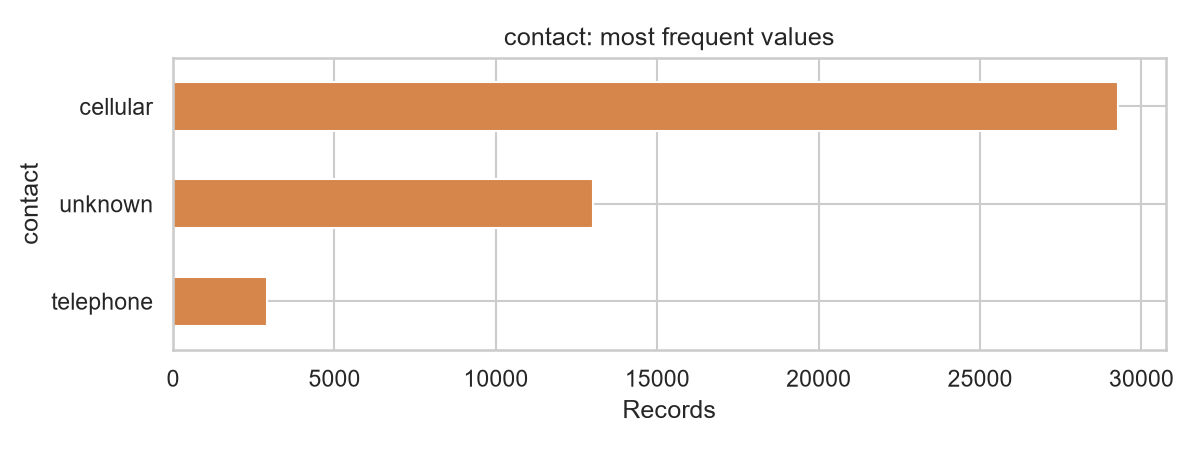

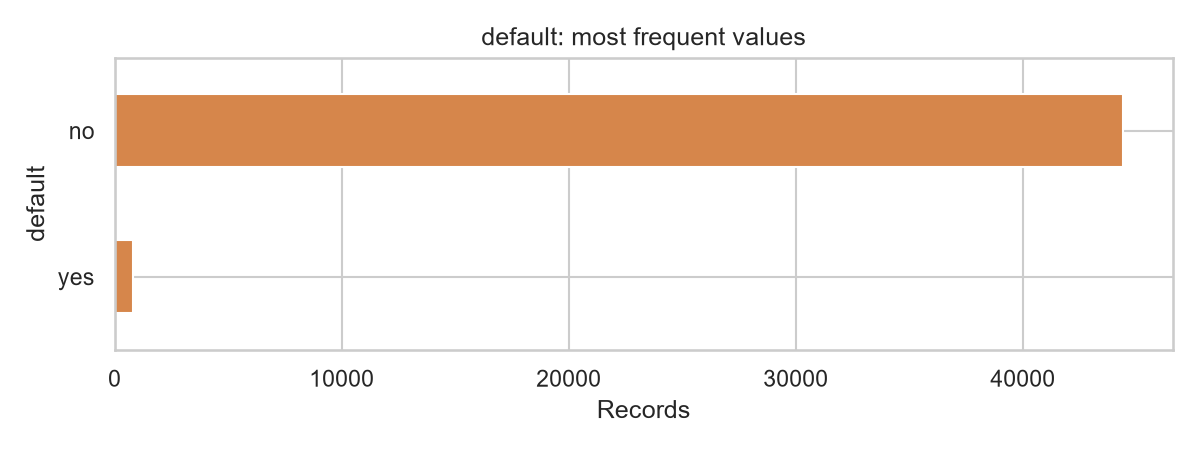

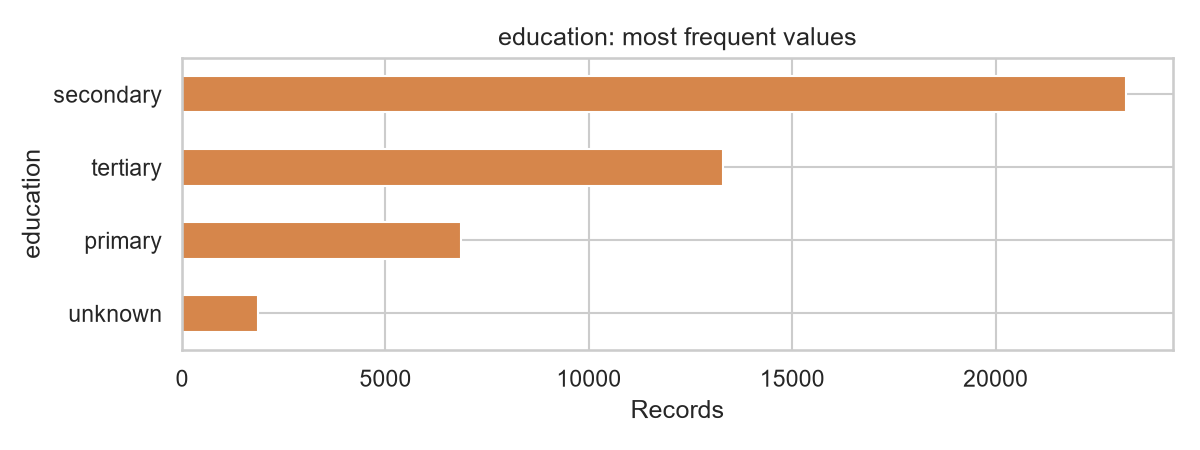

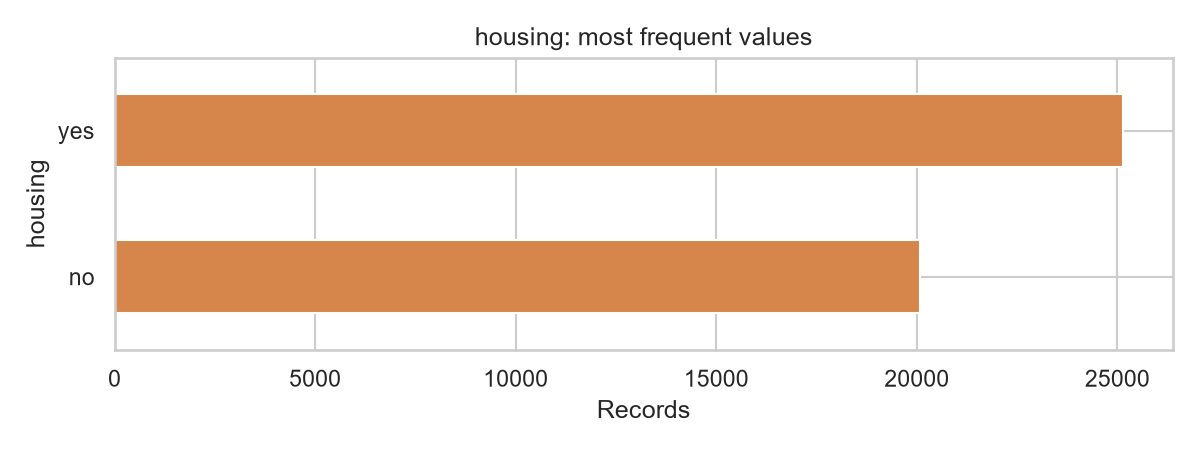

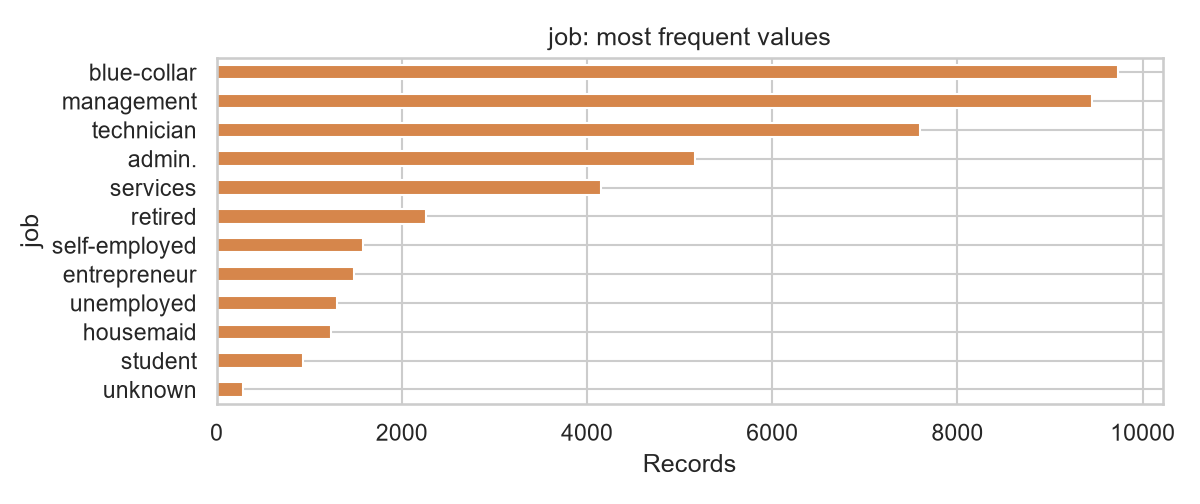

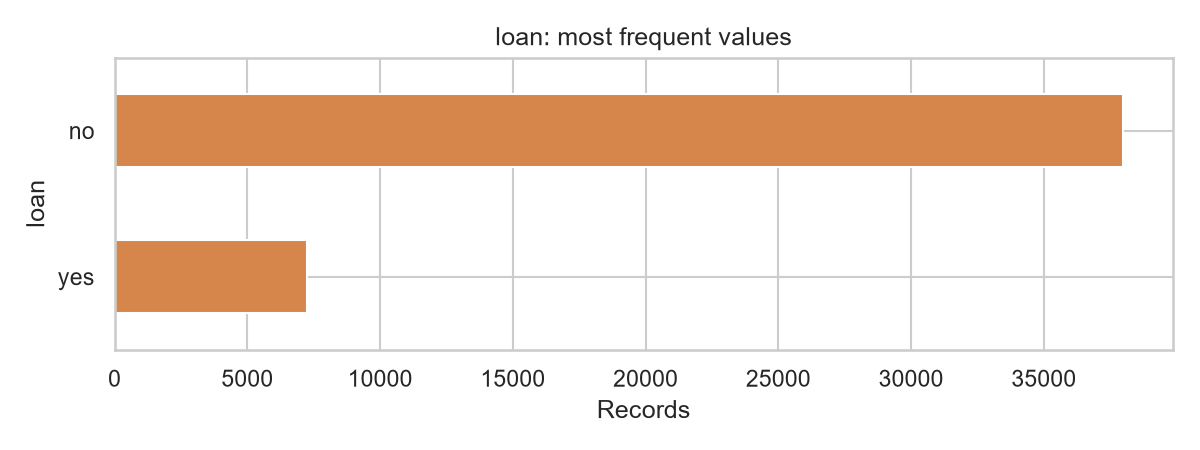

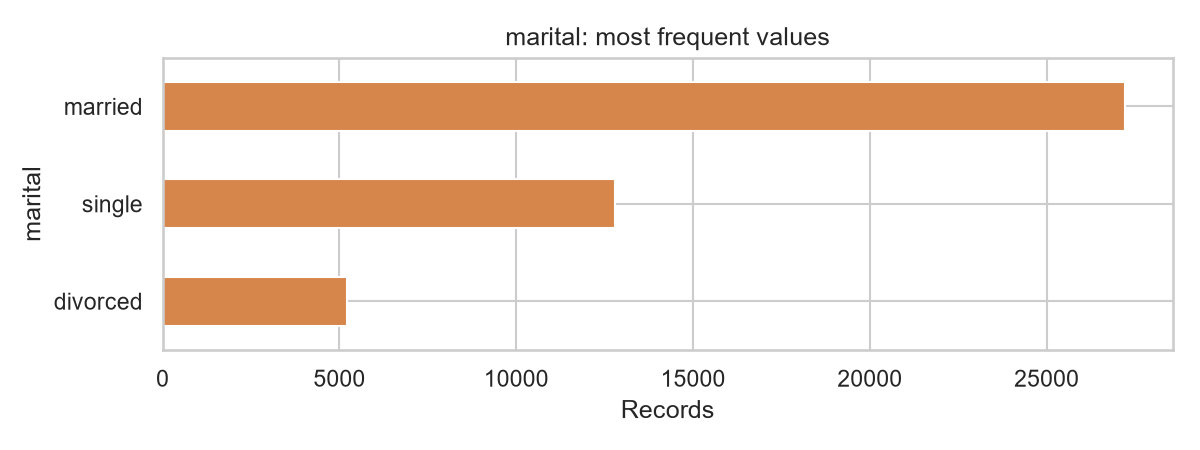

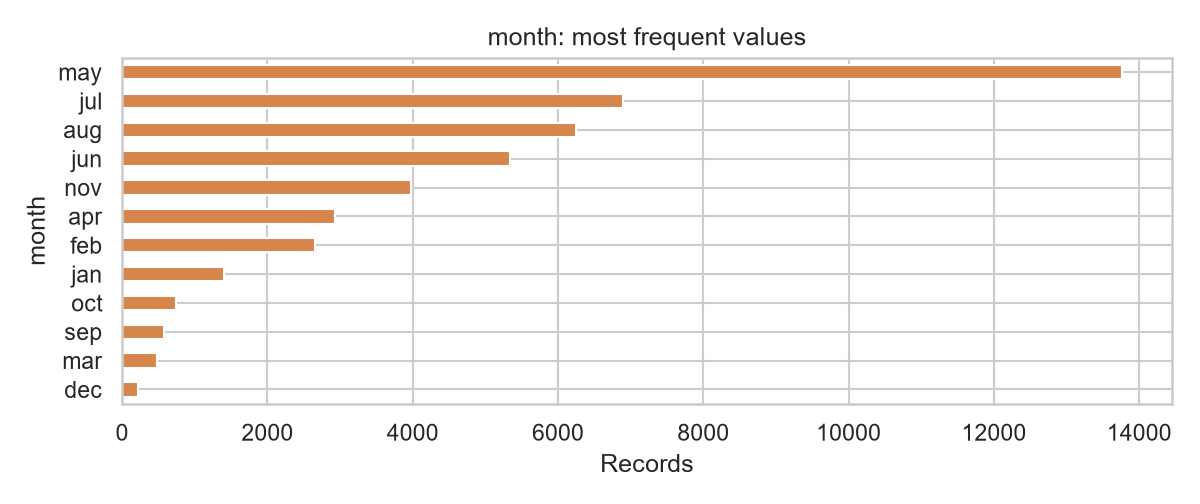

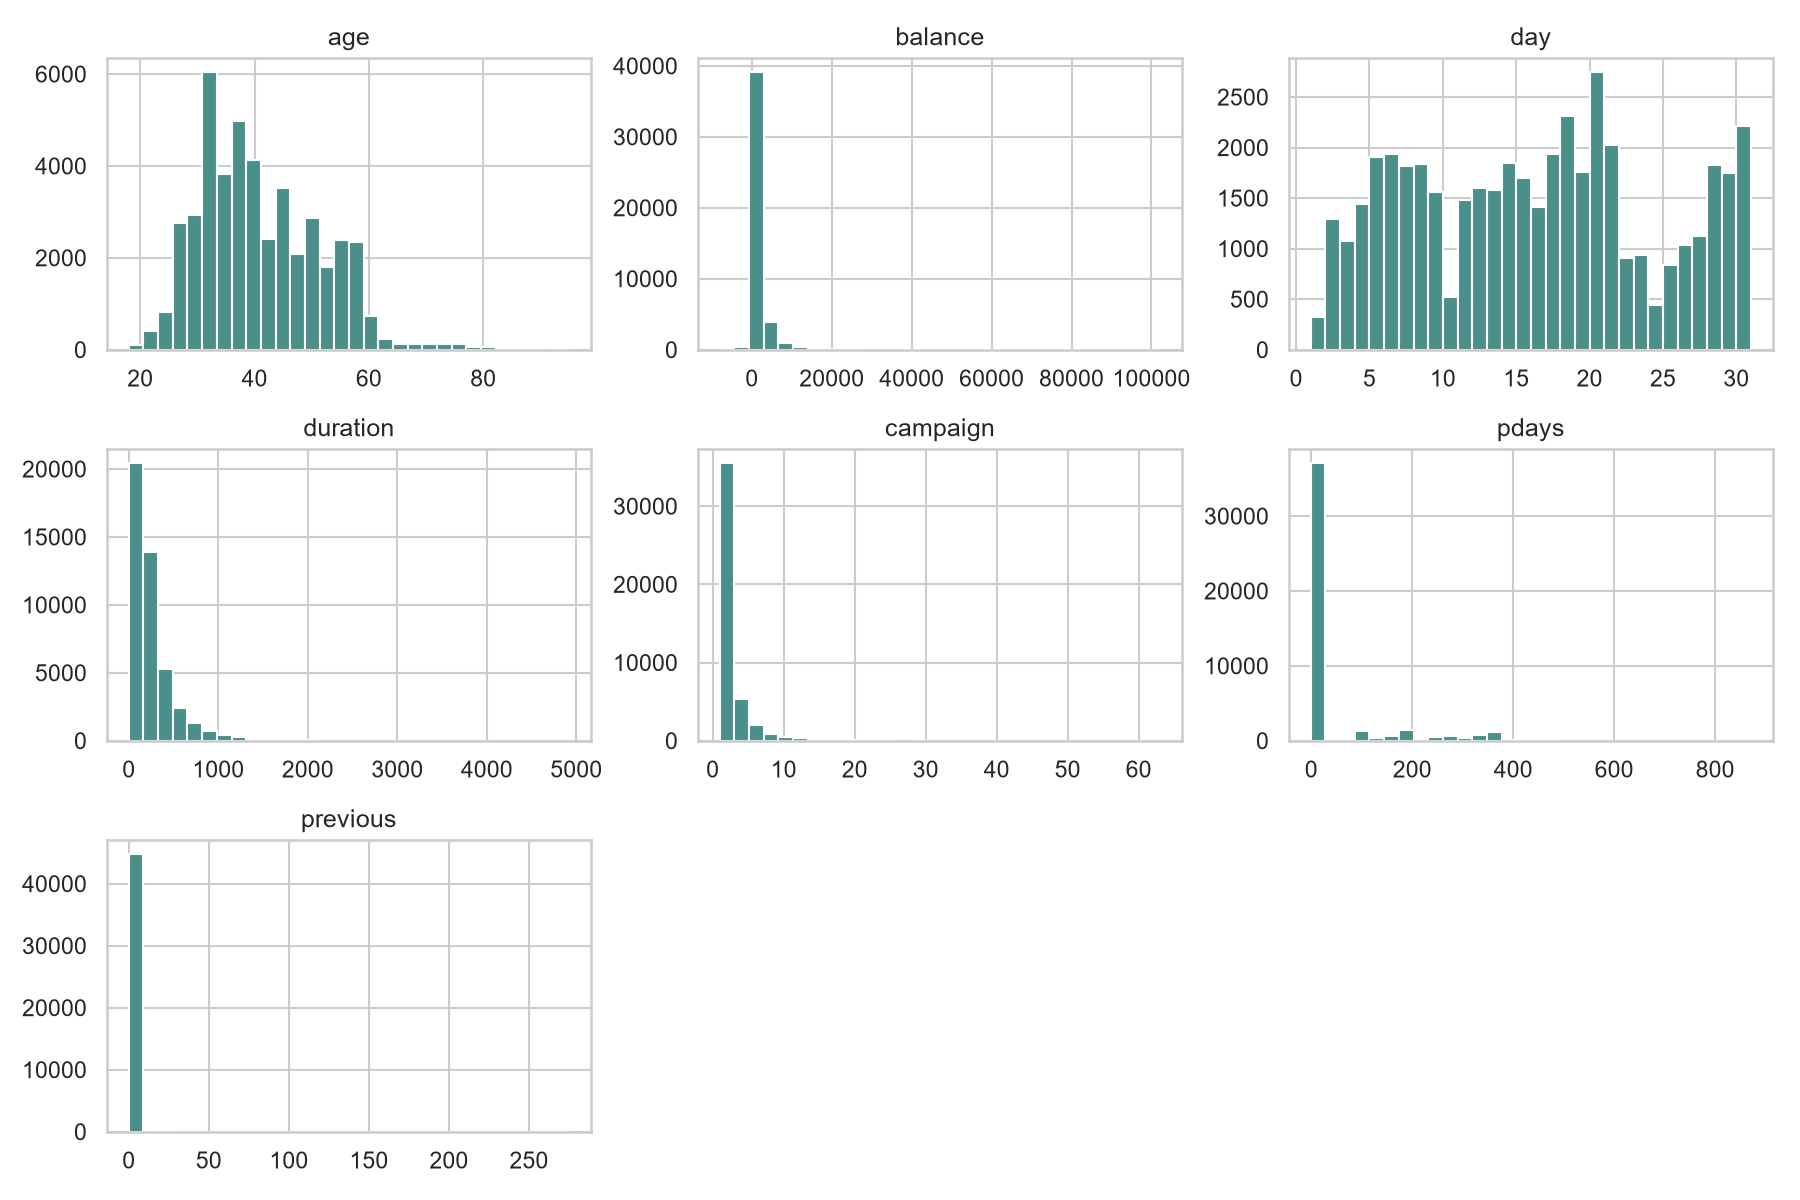

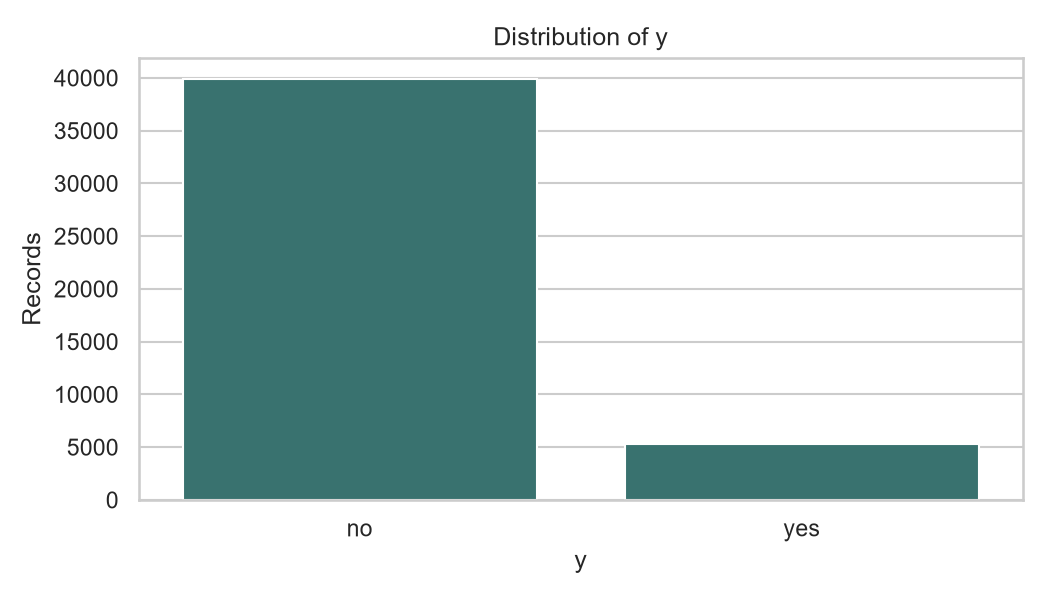

In [7]:
from src.analysis import run_analysis

results = run_analysis(DATA_PATH, target=TARGET, project_root=PROJECT_ROOT)
print("Data summary:")
print(json.dumps(results["profile"]["shape"], indent=2))
print("Segmentation:")
print(json.dumps(results["clustering"], indent=2, default=str))
print("Model evaluation:")
print(json.dumps(results["modeling"], indent=2, default=str))

from IPython.display import Image
for image_path in sorted((PROJECT_ROOT / "visualizations").glob("*.png")):
    display(Image(filename=str(image_path)))

## Actual results, recommendations, and reflection

Use the outputs above to write findings with their supporting counts/rates and holdout metrics. Do not make causal claims. Recommendations should account for campaign costs, capacity, fairness, and whether each feature is known at decision time. Record challenges encountered, successful checks, limitations, and next steps below only after reviewing the actual outputs.

### Evidence-based conclusion

The generated profile, segment scores, and holdout comparison are the empirical evidence for this project. If model evaluation or clustering reports `not_calculated`, state the returned reason rather than filling in a guessed result. The local file's source must be verified independently before citing UCI or Kaggle.